<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/Reglas_de_Asociacion_Groceries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1- instalar e importar librerías

In [ ]:
!pip install -q mlxtend

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

2- subir el archivo


In [ ]:
from google.colab import files
subido = files.upload()

Saving Groceries_dataset.csv to Groceries_dataset.csv


3. leer y mirar los datos

In [ ]:
import pandas as pd

df = pd.read_csv("Groceries_dataset.csv")
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


Paso 2: EDA (análisis exploratorio)

2.1 Tamaño y estructura

In [ ]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (38765, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


2.2 Valores nulos y duplicados

In [ ]:
print("Nulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
 Member_number      0
Date               0
itemDescription    0
dtype: int64

Filas duplicadas: 759


En este dataset puede haber duplicados. No los borres todavía: un mismo cliente puede comprar dos veces el mismo producto el mismo día. Solo anota cuántos hay.

2.3 Convertir la fecha

Las fechas vienen en formato día-mes-año, así que hay que avisarlo:

In [ ]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
print("Rango de fechas:", df["Date"].min(), "→", df["Date"].max())

Rango de fechas: 2014-01-01 00:00:00 → 2015-12-30 00:00:00


2.4 Cifras clave

In [ ]:
print("Clientes distintos:", df["Member_number"].nunique())
print("Productos distintos:", df["itemDescription"].nunique())

canastas = df.groupby(["Member_number", "Date"])["itemDescription"].nunique()
print("Transacciones (cliente + fecha):", len(canastas))
print("Tamaño promedio de la canasta:", round(canastas.mean(), 2))

Clientes distintos: 3898
Productos distintos: 167
Transacciones (cliente + fecha): 14963
Tamaño promedio de la canasta: 2.54


Cada combinación de cliente y fecha es una transacción.


2.5 Los 10 productos más vendidos

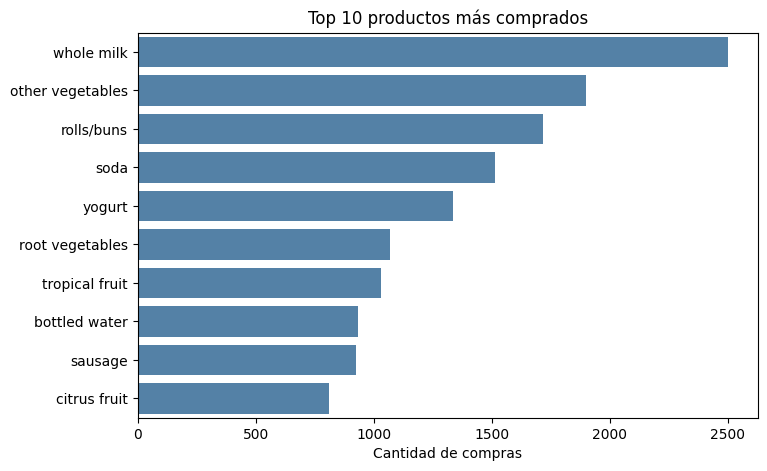

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top10 = df["itemDescription"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Top 10 productos más comprados")
plt.xlabel("Cantidad de compras")
plt.ylabel("")
plt.show()

Paso 3: preparar transacciones y aplicar Apriori

3.1 Armar las transacciones

In [ ]:
import pandas as pd

try:
    df
except NameError:
    df = pd.read_csv("Groceries_dataset.csv")
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

transacciones = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda x: list(set(x)))
      .tolist()
)
print("Número de transacciones:", len(transacciones))
print("Ejemplo:", transacciones[:3])

Número de transacciones: 14963
Ejemplo: [['pastry', 'whole milk', 'salty snack'], ['semi-finished bread', 'yogurt', 'sausage', 'whole milk'], ['soda', 'pickled vegetables']]


3.2 Convertir a matriz verdadero/falso

In [ ]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
matriz = pd.DataFrame(te.fit(transacciones).transform(transacciones), columns=te.columns_)
matriz.shape

(14963, 167)

3.3 Itemsets frecuentes con Apriori

In [ ]:
from mlxtend.frequent_patterns import apriori

frecuentes = apriori(matriz, min_support=0.001, use_colnames=True, max_len=3)
print("Itemsets frecuentes:", len(frecuentes))
frecuentes.sort_values("support", ascending=False).head(10)

Itemsets frecuentes: 750


,support,itemsets
146,0.157923,(whole milk)
90,0.122101,(other vegetables)
109,0.110005,(rolls/buns)
123,0.097106,(soda)
147,0.085879,(yogurt)
110,0.069572,(root vegetables)
139,0.067767,(tropical fruit)
10,0.060683,(bottled water)
115,0.060349,(sausage)
28,0.053131,(citrus fruit)


3.4 Reglas de asociación

In [ ]:
from mlxtend.frequent_patterns import association_rules

reglas = association_rules(frecuentes, metric="lift", min_threshold=1)
reglas = reglas[["antecedents", "consequents", "support", "confidence", "lift"]]
reglas.sort_values("lift", ascending=False).head(10)

,antecedents,consequents,support,confidence,lift
238,(sausage),"(yogurt, whole milk)",0.001470,0.024363,2.182917
235,"(yogurt, whole milk)",(sausage),0.001470,0.131737,2.182917
236,"(sausage, whole milk)",(yogurt),0.001470,0.164179,1.911760
237,(yogurt),"(sausage, whole milk)",0.001470,0.017121,1.911760
86,(citrus fruit),(specialty chocolate),0.001403,0.026415,1.653762
87,(specialty chocolate),(citrus fruit),0.001403,0.087866,1.653762
234,"(yogurt, sausage)",(whole milk),0.001470,0.255814,1.619866
239,(whole milk),"(yogurt, sausage)",0.001470,0.009310,1.619866
123,(tropical fruit),(flour),0.001069,0.015779,1.617141
122,(flour),(tropical fruit),0.001069,0.109589,1.617141


Paso 4: filtrar, visualizar y concluir

4.1 Cuántas reglas hay y cuántas transacciones respaldan cada una

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import association_rules

# Verificar si 'reglas' existe en memoria, de lo contrario volver a generarla
try:
    reglas
except NameError:
    reglas = association_rules(frecuentes, metric="lift", min_threshold=1)
    reglas = reglas[["antecedents", "consequents", "support", "confidence", "lift"]]

print("Total de reglas:", len(reglas))

n = len(transacciones)
reglas["n_transacciones"] = (reglas["support"] * n).round().astype(int)
reglas.head()

Total de reglas: 240


,antecedents,consequents,support,confidence,lift,n_transacciones
0,(UHT-milk),(tropical fruit),0.001537,0.071875,1.060617,23
1,(tropical fruit),(UHT-milk),0.001537,0.022682,1.060617,23
2,(brown bread),(beef),0.001537,0.040853,1.203301,23
3,(beef),(brown bread),0.001537,0.045276,1.203301,23
4,(citrus fruit),(beef),0.001804,0.033962,1.000349,27


4.2 Reglas más útiles (ordenadas por confianza)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

mejores = reglas[(reglas["lift"] > 1.2) & (reglas["confidence"] >= 0.10)]
mejores = mejores.sort_values("confidence", ascending=False)
print("Reglas filtradas:", len(mejores))
mejores.head(10)

Reglas filtradas: 15


,antecedents,consequents,support,confidence,lift,n_transacciones
234,"(yogurt, sausage)",(whole milk),0.001470,0.255814,1.619866,22
216,"(rolls/buns, sausage)",(whole milk),0.001136,0.212500,1.345594,17
236,"(sausage, whole milk)",(yogurt),0.001470,0.164179,1.911760,22
180,(processed cheese),(rolls/buns),0.001470,0.144737,1.315734,22
176,(packaged fruit/vegetables),(rolls/buns),0.001203,0.141732,1.288421,18
186,(seasonal products),(rolls/buns),0.001002,0.141509,1.286395,15
235,"(yogurt, whole milk)",(sausage),0.001470,0.131737,2.182917,22
205,(soft cheese),(yogurt),0.001270,0.126667,1.474952,19
115,(detergent),(yogurt),0.001069,0.124031,1.444261,16
171,(oil),(soda),0.001804,0.121076,1.246844,27


4.3 Gráfico de las reglas

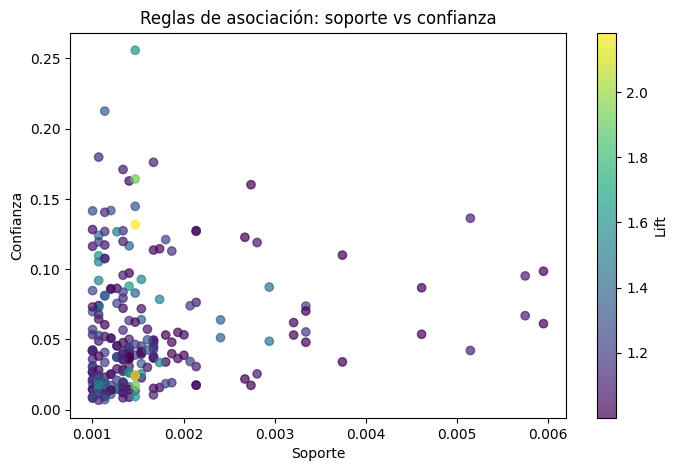

In [ ]:
plt.figure(figsize=(8, 5))
sc = plt.scatter(reglas["support"], reglas["confidence"],
                 c=reglas["lift"], cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Lift")
plt.xlabel("Soporte")
plt.ylabel("Confianza")
plt.title("Reglas de asociación: soporte vs confianza")
plt.show()

# Conclusion:

**Datos**: se analizaron 14.963 transacciones (cliente + fecha), 3.898 clientes y 167 productos. Las canastas son pequeñas (2,54 productos en promedio). Los productos más comprados son whole milk, other vegetables, rolls/buns, soda y yogurt.



**Modelo**: con Apriori (soporte mínimo 0,1 %) se obtuvieron 750 itemsets frecuentes y 240 reglas de asociación. Tras filtrar por lift > 1,2 y confianza ≥ 10 %, quedaron 15 reglas.


**Hallazgos principales**:
Quienes compran yogurt y salchichas llevan además leche entera en el 25,6 % de los casos (lift 1,62).
La asociación más fuerte es entre (yogurt, leche entera) y salchichas, con lift 2,18: se compran juntos más del doble de lo esperado por azar.
También hay asociaciones entre quesos y yogurt o pan (rolls/buns), con lift entre 1,3 y 1,5.


**Limitaciones**: los soportes son muy bajos (≈ 0,1 %–0,2 %), de modo que cada regla se apoya en pocas decenas de transacciones. Las asociaciones son moderadas y podrían ser casualidad. En este dataset no hay combinaciones de productos fuertes ni frecuentes.

**Aplicación posible**: ubicar cerca o promocionar juntos yogurt, leche entera y salchichas, o quesos con yogurt. Antes de aplicarlo en un negocio real convendría validarlo con más datos.